In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pysam
from pathlib import Path
import msprime

ModuleNotFoundError: No module named 'pysam'

# A. Lecture des données

In [ ]:
CHROM = '22'  # chromosome (21 et 22 sont les plus petits : ~0,9 Go)

BASE_URL = "https://sharehost.hms.harvard.edu/genetics/reich_lab/sgdp/phased_data2021/"
SRC      = BASE_URL + f"chr.sgdp.pub.{CHROM}.bcf"


In [ ]:
# 1. Ouvrir à distance : seul l'en-tête dest lu
vf = pysam.VariantFile(SRC, index_filename=SRC + ".csi")
samples = pd.DataFrame(list(vf.header.samples), columns=['Sample'])
print(len(samples), "individus")
display(samples)
# On veut sélectionner les individus de l'article : S_French-1, S_French-2, S_Yoruba-1, S_Yoruba-2
samples_article = samples[samples["Sample"].str.contains("French-1|French-2|Yoruba-1|Yoruba-2")]
display(samples_article)

[W::bcf_hdr_check_sanity] GP should be declared as Number=G


278 individus


,Sample
0,B_Australian-3.DG
1,B_Australian-4.DG
2,B_Crete-1.DG
3,B_Crete-2.DG
4,B_Dai-4.DG
...,...
273,S_Yi-2.DG
274,S_Yoruba-1.DG
275,S_Yoruba-2.DG
276,S_Zapotec-1.DG


,Sample
92,S_French-1.DG
93,S_French-2.DG
274,S_Yoruba-1.DG
275,S_Yoruba-2.DG


In [ ]:
# 2. Lire une petite région (100 kb=kilobases) pour 1 individu
ind = samples_article["Sample"].iloc[0]     # on choisit par exemple le premier individu (S_French-1)
print(repr(ind))                            # repr montre aussi les espaces ou caractères cachés
contig = CHROM if CHROM in vf.header.contigs else "chr" + CHROM
vf.subset_samples([ind])
rows = []
for rec in vf.fetch(contig, 20_000_000, 20_100_000):      # 0-based, fin exclue
    s = rec.samples[ind]
    rows.append({"POS": rec.pos, "REF": rec.ref,
                 "ALT": ",".join(rec.alts or []),
                 "GT": "|".join("." if a is None else str(a) for a in s["GT"]),
                 "phase": s.phased})
df = pd.DataFrame(rows)
print(df.shape) # (nombre de sites, nombre de colonnes=5)
df.head()

'S_French-1.DG'
(3088, 5)


,POS,REF,ALT,GT,phase
0,20000018,G,A,0|0,True
1,20000086,T,C,0|0,True
2,20000103,C,T,0|0,True
3,20000146,G,A,0|0,True
4,20000199,A,C,0|0,True


Une ligne = un site variant dans la région lue (100 kb du chromosome 22). « Variant » veut dire qu’au moins un des individus du jeu de données y porte une lettre différente de la référence, pas forcément ton individu.

`df.shape` donne `(nombre de sites, 5)`. Les cinq colonnes :

* **POS** : position du site sur le chromosome (1 = première base)
* **REF** : la lettre du génome de référence humain à cette position
* **ALT** : la lettre alternative (plusieurs, séparées par des virgules, si le site est multiallélique)
* **GT** : le génotype de ton individu, `a|b` : allèle de sa copie 1, allèle de sa copie 2 (0 = REF, 1 = ALT)
* **phase** : `True` si le génotype est phasé

<u> Comment lire une ligne ? </u>

Par exemple `POS=20000123`, `REF=A`, `ALT=G`, `GT=0|1` veut dire : à cette position, la copie 1 de l’individu porte `A` et la copie 2 porte `G`. L’individu est hétérozygote à ce site.

* **0|0 et 1|1** : ses deux copies sont identiques à ce site, donc ce n’est pas une donnée pour nous.
* **0|1 et 1|0** : ses deux copies diffèrent. Ce sont les seules lignes utiles au modèle à $n = 2$ : leurs positions sont les observations $y$.


<u> Remarque : ce que veut dire « phasé ». </u>

Un individu a deux copies de chaque chromosome. Le séquençage indique quelles lettres il porte, mais pas toujours sur quelle copie se trouve chacune.

Non phasé (0/1) : on sait que l’individu porte un A et un G, mais pas lequel est sur la copie de la mère et lequel sur celle du père.
Phasé (0|1) : on sait aussi sur quelle copie se trouve chaque lettre. D’un site au suivant, « copie 1 » désigne toujours la même copie physique. On peut donc reconstituer les deux séquences complètes, les haplotypes.

Dans ce jeu, le phasage a été estimé statistiquement (GLIMPSE), donc phase devrait valoir True partout.

Pour n = 2, le phasage n’a pas d’importance : un site hétérozygote reste hétérozygote, quel que soit le sens. Il devient indispensable à partir de n = 4 (deux individus), pour savoir quelles copies portent la mutation, c’est-à-dire pour construire le motif A_j.

In [ ]:
# 3. Premier regard sur la structure
print(df.shape)
print(df["GT"].value_counts())         # 0|0, 0|1, 1|0, 1|1
het = df[df["GT"].isin(["0|1", "1|0"])]
print(len(het), "sites hétérozygotes sur 100 kb")

(3088, 5)
GT
0|0    3035
1|1      53
Name: count, dtype: int64
0 sites hétérozygotes sur 100 kb


# B. Simulation des données

Le but est de vérifier que le filtre retrouve les bons arbres quand on l'utilise sur des données simulées pour lesquelles on connaît les dates de coalescence. Ensuite, on pourra lui faire confiance sur des données réelles (pour lesquelles on ne connaît pas la ground truth).

On commence avec le cas de 2 haplotypes (donc 1 individu diploïde), l'arbre local (l'état caché $x_s$) à reconstruire pour le site $s$ est alors juste la date (notée $T_s$) de coalescence au site $s$.

| Étape | Ce qu’on utilise | Ce qu’on produit | Rôle |
| :--- | :--- | :--- | :--- |
| **1. Fixer le « vrai monde »** | Rien | $N_e = 10\,000$, $\mu = 1{,}25 \times 10^{-8}$, $\rho = 10^{-8}$ | Les paramètres vrais |
| **2. Simuler l’histoire cachée** | Les paramètres | La vraie suite des $T_s$ le long de 2 Mb | Vérité terrain : on la met de côté |
| **3. Simuler les observations** | Les vrais $T_s$ et $\mu$ | Les positions des sites hétérozygotes | Les données : même structure que les lignes `0|1` / `1|0` de ton `df` |
| **4. Lancer le filtre bootstrap** | Seulement les données et les paramètres (jamais la vérité terrain) | À chaque waypoint : $N$ particules pondérées | La prédiction |
| **5. Comparer à la vérité** | La prédiction et la vérité terrain | Courbes, erreurs, variabilité | Juger le filtre |
| **6. Passer aux vraies données** | Les sites hétérozygotes de `df`, les mêmes paramètres | Même sortie qu’à l’étape 4 | Sans vérité : seulement des contrôles de cohérence |

In [ ]:
# 1. Paramètres de l'article
Ne = 10_000      # taille efficace, ground truth
mu = 1.25e-8     # taux de mutation (par base et par génération)
rho = 1e-8       # taux de recombinaison (par base et par génération)
C = 1 / (2 * Ne) # taux de coalescence

In [ ]:
# 2. Simuler les données 
L = 2_000_000
ts  = msprime.sim_ancestry(samples=1, ploidy=2, population_size=Ne, sequence_length=L,
                           recombination_rate=rho, model="smc_prime", random_seed=2)            # simule les arbres ancestraux
mts = msprime.sim_mutations(ts, rate=mu, model=msprime.BinaryMutationModel(), random_seed=3)    # place les mutations sur ces arbres
G   = mts.genotype_matrix()                                                                     # matrcie avec une ligne par site muté, et une colonne par haplotype (0=ancestral, 1=dérivé)
het = np.sort(mts.tables.sites.position[G.sum(1) == 1])                                         # observations : positions des hétérozygotes
truth = np.array([(t.interval.left, t.interval.right, t.time(t.root)) for t in ts.trees()])     # vrai T_s par segment
print(len(het), "sites hétérozygotes")
print(G.shape)

961 sites hétérozygotes
(961, 2)


In [ ]:
# 3. Dynamique (noyau de transition) : coalescence et recombinaison
def recombine(T, rng):
    nu = rng.uniform(0, T)                                      # date de la coupure
    e = rng.exponential(1 / (2 * C), size=T.shape)              # temps d'attente sous T (2 lignées)
    below = nu + e < T
    own = rng.random(T.shape) < 0.5                             # rattachement à sa propre branche : invisible
    return np.where(below, np.where(own, T, nu + e),            # nouveau T
                    T + rng.exponential(1 / C, size=T.shape))   #    ou au-dessus de la racine

In [ ]:
# 4. Filtre Bootstrap (pour un seul individu, donc 2 haplotypes)
def bootstrap_filter(het, L, N=1000, W=500, seed=0):
    rng = np.random.default_rng(seed)
    T = rng.exponential(1 / C, N)                 # M_0 : T ~ Exp(C), la loi de la coalescence
    logw, loglik = np.zeros(N), 0.0
    grid = np.arange(0, L + W, W)                 # waypoints
    meanT, ess = [], []
    for a, b in zip(grid[:-1], grid[1:]):
        # rééchantillonnage (systématique) si ESS < N/2
        w = np.exp(logw - logw.max()); Wn = w / w.sum()
        if 1 / np.sum(Wn**2) < N / 2:
            loglik += logw.max() + np.log(w.mean())
            u = (rng.random() + np.arange(N)) / N
            T, logw = T[np.minimum(np.searchsorted(np.cumsum(Wn), u), N - 1)], np.zeros(N)
        # propagation M_t sur [a, b) et poids G_t
        x, active = np.full(N, float(a)), np.ones(N, bool)
        while active.any():
            d = rng.exponential(1 / (2 * rho * T))                    # distance à la prochaine recombinaison
            end = np.where(active, np.minimum(x + d, b), x)
            k = np.searchsorted(het, end) - np.searchsorted(het, x)   # nb d'hétérozygotes dans [x, end)
            logw += np.where(active, -2 * mu * T * (end - x) + k * np.log(2 * mu * T), 0.0)
            jump = active & (x + d < b)
            T = np.where(jump, recombine(T, rng), T)
            x, active = end, jump
        w = np.exp(logw - logw.max()); Wn = w / w.sum()
        meanT.append(np.sum(Wn * T)); ess.append(1 / np.sum(Wn**2))
    w = np.exp(logw - logw.max()); loglik += logw.max() + np.log(w.mean())
    return grid[1:], np.array(meanT), np.array(ess), loglik

log-vraisemblance : -8045.4  ESS min : 7.0


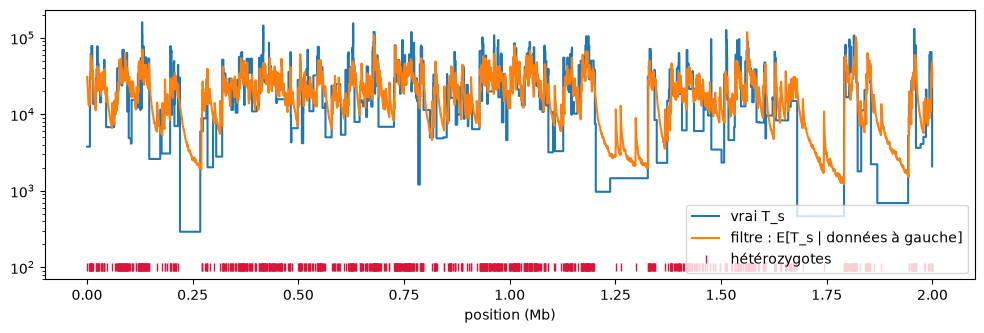

In [ ]:
# 5. Filtre Bootstrap sur les données simulées
pos_grid, meanT, ess, ll = bootstrap_filter(het, L)
print("log-vraisemblance :", round(ll, 1), " ESS min :", ess.min().round())
plt.figure(figsize=(12, 3.5))
plt.step(truth[:, 0] / 1e6, truth[:, 2], where="post", label="vrai T_s")
plt.plot(pos_grid / 1e6, meanT, label="filtre : E[T_s | données à gauche]")
plt.plot(het / 1e6, np.full(len(het), 100), "|", color="crimson", label="hétérozygotes")
plt.yscale("log"); plt.xlabel("position (Mb)"); plt.legend(); plt.show()

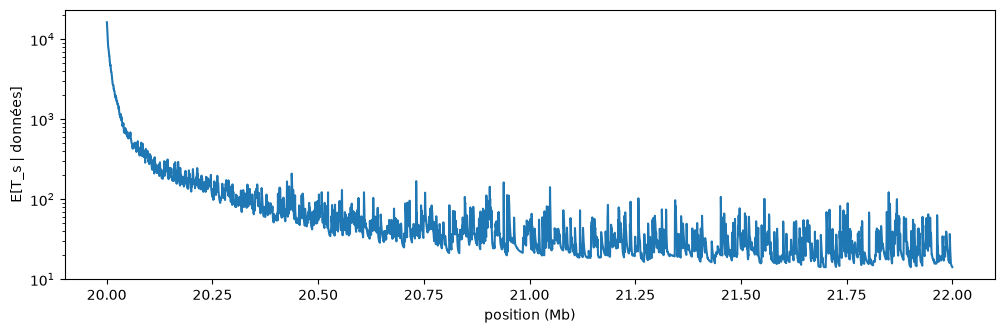

In [ ]:
# 6. Filtre Bootstrap appliqué aux données réelles
start, end = 20_000_000, 22_000_000
het_real = np.sort(df.loc[df["GT"].isin(["0|1", "1|0"]), "POS"].to_numpy() - start).astype(float)
pos_r, meanT_r, ess_r, ll_r = bootstrap_filter(het_real, end - start)
plt.figure(figsize=(12, 3.5))
plt.plot((pos_r + start) / 1e6, meanT_r); plt.yscale("log")
plt.xlabel("position (Mb)"); plt.ylabel("E[T_s | données]"); plt.show()

Remarques : 
- les données simulées et le bootstrap filter ne considèrent que n=2 haplotypes (donc issus d'un même individu). Pour passer à n=8 (4 individus comme dans l'article), il faut généraliser.
- T est exprimé en nombre de générations, pas en années (dans l'article ils multiplient par g=30 ans)